In [1]:
import os, sys, glob, io, contextlib, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # e.g. Bischoff2021_Lung-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Lung
data_name = re.sub(r'-\d+$', '', name)                  # strip attempt suffix -> Bischoff2021_Lung
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', 'Data_'+data_name)

dataset: Bischoff2021_Lung-2 | category: Lung | input: Data_Bischoff2021_Lung


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells on the manifold:', adata.shape[0])
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect (major/minor std): {s[0]/s[1]:.2f}  (~1.3 -> 2-D continuum, not a 1-D strip)')

cells on the manifold: 13382
UMAP aspect (major/minor std): 1.37  (~1.3 -> 2-D continuum, not a 1-D strip)


In [4]:
# CURVE vs TREE read from the embedding (render actual edges to catch folds).
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    deg=(B>0).sum(0)
    return dmin/med_edge, int((deg==1).sum()), int((deg>=3).sum())
adc = adata.copy(); adt = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adc, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    scf.tl.tree(adt, method='ppt', Nodes=20, use_rep='X_umap', ppt_sigma=1.5, ppt_lambda=1.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(adc); sat,tipst,forkst = fold_diag(adt)
print(f'CURVE: {tips} tips, {forks} forks | fold self-approach = {sa:.2f} (>1 fold-free)')
print(f'TREE : {tipst} tips, {forkst} forks | fold self-approach = {sat:.2f}')

CURVE: 2 tips, 0 forks | fold self-approach = 2.90 (>1 fold-free)
TREE : 4 tips, 2 forks | fold self-approach = 1.22


In [5]:
# Do the TREE forks carry biology (Gast vs pSom separation)? If tips are biologically
# identical the branches chase density, not a bifurcation -> non-branching case.
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adt, gene_list=list(g), score_name=l, ctrl_as_ref=False, gene_pool=list(g_ref), random_state=1234)
# smooth for geography
A=(adt.obsp['connectivities']>0).astype(float); A=A+sp.eye(A.shape[0]); A=sp.diags(1/np.array(A.sum(1)).ravel())@A
S=adt.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S=A@S
for j,l in enumerate(['Gast','pSom','Crest']): adt.obs[l+'_sm']=S[:,j]
Bt=np.asarray(adt.uns['graph']['B']); tps=np.where((Bt>0).sum(0)==1)[0]
R=np.asarray(adt.obsm['X_R']); hard=R.argmax(1); Dt=shortest_path(sp.csr_matrix((Bt>0).astype(int)),unweighted=True)
print('TREE tip biology (curve chosen if tips are biologically identical):')
for t in tps:
    m=np.isin(hard,np.where(Dt[t]<=3)[0])
    print(f'  tip {t}: n={m.sum():5d} Gast={adt.obs["Gast_sm"][m].mean():+.3f} pSom={adt.obs["pSom_sm"][m].mean():+.3f} Crest={adt.obs["Crest_sm"][m].mean():+.3f}')

TREE tip biology (curve chosen if tips are biologically identical):
  tip 0: n= 3355 Gast=-0.032 pSom=+0.062 Crest=-0.042
  tip 3: n= 2440 Gast=-0.040 pSom=+0.061 Crest=-0.039
  tip 5: n= 4191 Gast=-0.035 pSom=+0.047 Crest=-0.022
  tip 11: n= 2965 Gast=-0.032 pSom=+0.062 Crest=-0.041


Non-branching case: curve is fold-free with 0 forks; tree forks separate no biology.


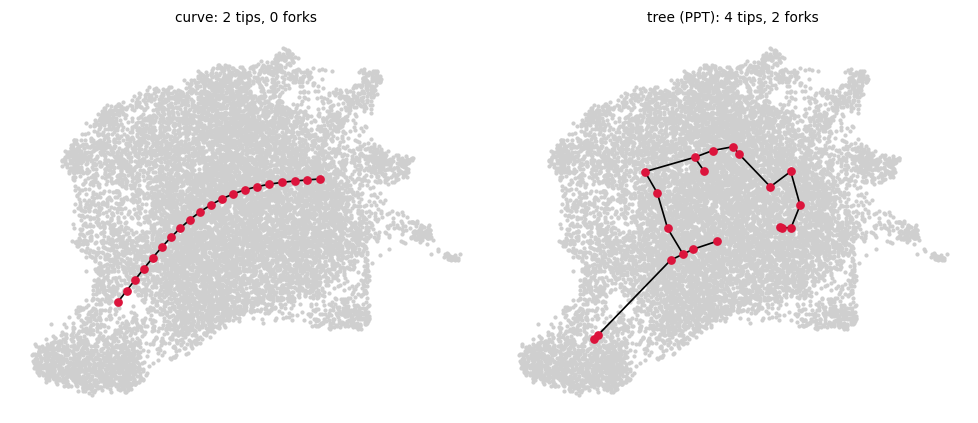

In [6]:
# render curve vs tree WITH the fitted edges on the embedding
fig, axes = plt.subplots(1,2, figsize=(9,3.8))
for ax, ad, nm in [(axes[0],adc,'curve'),(axes[1],adt,'tree (PPT)')]:
    ax.scatter(ad.obsm['X_umap'][:,0], ad.obsm['X_umap'][:,1], s=3, c='#cfcfcf')
    B=np.asarray(ad.uns['graph']['B']); F=ad.uns['graph']['F'].T
    ii,jj=np.where(np.triu(B>0))
    for a,b in zip(ii,jj): ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]],'-',c='k',lw=1.1)
    ax.scatter(F[:,0],F[:,1],s=22,c='crimson',zorder=5)
    deg=(B>0).sum(0); ax.set_title(f'{nm}: {int((deg==1).sum())} tips, {int((deg>=3).sum())} forks',size=9); ax.set_aspect('equal'); ax.axis('off')
fig.tight_layout(); plt.show()
print('Non-branching case: curve is fold-free with 0 forks; tree forks separate no biology.')

In [7]:
# fit the CURVE on the whole manifold, root at the developmental origin (Gast/pSom-high,
# Crest-LOW; neural crest is developmentally LATE, so it is NOT the root), pseudotime.
adata = adc  # curve fit
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False, gene_pool=list(g_ref), random_state=1234)
A=(adata.obsp['connectivities']>0).astype(float); A=A+sp.eye(A.shape[0]); A=sp.diags(1/np.array(A.sum(1)).ravel())@A
S=adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S=A@S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm']=S[:,j]
B=np.asarray(adata.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
R=np.asarray(adata.obsm['X_R']); hard=R.argmax(1); D=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
info={}
for t in tps:
    m=np.isin(hard,np.where(D[t]<=3)[0])
    info[t]=dict(Gast=adata.obs['Gast_sm'][m].mean(),pSom=adata.obs['pSom_sm'][m].mean(),Crest=adata.obs['Crest_sm'][m].mean(),
                 alv=(adata.obs['axis'][m]=='Alveolar').mean(),emt=(adata.obs['axis'][m]=='EMT').mean())
    print(f'tip {t}: Gast={info[t]["Gast"]:+.3f} pSom={info[t]["pSom"]:+.3f} Crest={info[t]["Crest"]:+.3f} | alv={info[t]["alv"]:.2f} emt={info[t]["emt"]:.2f}')
root = int(max(tps, key=lambda t: info[t]['Gast']+info[t]['pSom']-info[t]['Crest']))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low, Alveolar pole)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
print('pseudotime range', round(adata.obs['t'].min(),2), '->', round(adata.obs['t'].max(),2))
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(adata.obs['t'], adata.obs[s]); print(f'  {s} vs pseudotime rho={rho:+.3f}')

tip 0: Gast=-0.032 pSom=+0.061 Crest=-0.039 | alv=0.44 emt=0.00
tip 2: Gast=-0.042 pSom=+0.059 Crest=-0.032 | alv=0.01 emt=0.32
derived root = tip 0 (Gast/pSom-high, Crest-low, Alveolar pole)
pseudotime range 0.0 -> 10.23
  Gast_sm vs pseudotime rho=-0.536
  pSom_sm vs pseudotime rho=-0.001
  Crest_sm vs pseudotime rho=+0.240


saved manifold.h5ad + manifold.pdf


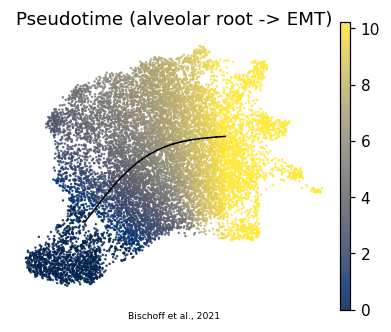

In [8]:
# manifold.pdf — pseudotime on the 2-D manifold with the fitted curve overlaid.
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
B=np.asarray(adata.uns['graph']['B']); F=adata.uns['graph']['F'].T
fig, ax = plt.subplots(figsize=(4.2,3.4))
sc.pl.umap(adata, color='t', cmap='cividis', size=10, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime (alveolar root -> EMT)')
ii,jj=np.where(np.triu(B>0))
for a,b in zip(ii,jj): ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]],'-',c='k',lw=1.0,zorder=5)
ax.set_aspect('equal')
ax.text(.5,-.08,'Bischoff et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')